# Notebook 12 – Business Insights
## `12_Business_Insights.ipynb`

### Learning objectives
Convert EDA findings into clear, evidence-based observations and useful business insights. The goal is to move from **visualization → observation → insight → action**.

This notebook uses example retail data. The values are illustrative, not real company results.

## 1. What is a business insight?

A **business insight** is an evidence-based interpretation of data that helps explain what may be happening and supports a decision.

- **Visualization:** a graph or chart.
- **Observation:** a factual pattern visible in the data.
- **Insight:** what that pattern may mean in context.
- **Action:** a practical next step to test or address it.

**Simple example:** A chart shows one student scores higher in mathematics. The observation is the score difference; an insight might be that the student is stronger in that subject, but more evidence is needed.

**Real-world example:** A transport team finds delays are concentrated at a particular time of day.

**Business example:** A retailer finds one category produces high revenue but low profit.

**AI/ML use case:** Insights help define prediction targets, useful features, segments, and business success metrics.

**Why it matters:** Data analysis should help answer a decision question, not just produce charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

orders = pd.DataFrame({
    "order_id": range(1, 16),
    "category": ["A","A","A","A","A","B","B","B","B","C","C","C","C","C","C"],
    "segment": ["Consumer","Business","Consumer","Home Office","Consumer",
                "Consumer","Business","Consumer","Home Office",
                "Consumer","Consumer","Business","Home Office","Consumer","Business"],
    "sales": [500, 450, 520, 480, 550, 300, 320, 280, 310, 120, 150, 110, 130, 140, 125],
    "profit": [90, 70, 100, 65, 110, 35, 30, 20, 40, -10, 5, -15, -5, 0, -8],
    "discount_pct": [5, 10, 0, 15, 5, 10, 20, 15, 5, 25, 20, 30, 25, 20, 35],
    "delivery_days": [2, 3, 2, 4, 2, 3, 5, 4, 3, 6, 5, 7, 6, 5, 8]
})
orders.head()

,order_id,category,segment,sales,profit,discount_pct,delivery_days
0,1,A,Consumer,500,90,5,2
1,2,A,Business,450,70,10,3
2,3,A,Consumer,520,100,0,2
3,4,A,Home Office,480,65,15,4
4,5,A,Consumer,550,110,5,2


## 2. Important patterns

A **pattern** is a repeated or noticeable structure in the data, such as one category consistently having higher sales.

**Simple example:** A student regularly performs better on quizzes after practicing.

**Real-world example:** Traffic is repeatedly heavier on weekday mornings.

**Business example:** A product category contributes a large share of revenue.

**AI/ML use case:** Repeated patterns may become features or hypotheses for predictive modeling.

**Why it matters:** Patterns help prioritize investigation, but they should be checked against enough observations and relevant context.

In [2]:
category_summary = orders.groupby("category", as_index=False).agg(
    order_count=("order_id", "count"),
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    average_discount=("discount_pct", "mean")
)
category_summary["sales_share_pct"] = (
    category_summary["total_sales"] / category_summary["total_sales"].sum() * 100
).round(1)
category_summary

,category,order_count,total_sales,total_profit,average_discount,sales_share_pct
0,A,5,2500,435,7.000000,55.7
1,B,4,1210,125,12.500000,27.0
2,C,6,775,-33,25.833333,17.3


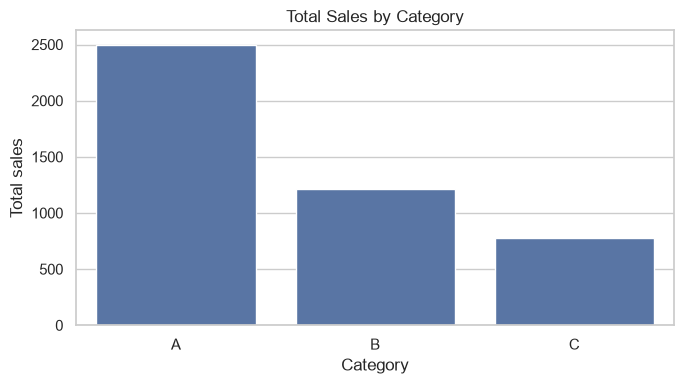

In [3]:
plt.figure(figsize=(7, 4))
sns.barplot(data=category_summary, x="category", y="total_sales")
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total sales")
plt.tight_layout()
plt.show()

**Observation:** Compare each category's total sales and share in the summary table.

**Insight example:** If Category A has the largest sales share, it is an important revenue contributor. That does not automatically mean it is the most profitable—check profit separately.

**Possible action:** Protect availability of high-performing products and investigate profitability before increasing promotion.

## 3. Trends

A **trend** is a general direction over an ordered sequence, often time.

**Simple example:** A learner's practice scores improve week by week.

**Real-world example:** Average temperatures rise over a season.

**Business example:** Weekly revenue rises or falls over several months.

**AI/ML use case:** Trend and seasonality analysis can inform time-series forecasting.

**Why it matters:** Trends support planning, but short-term fluctuations should not be mistaken for a long-term pattern.

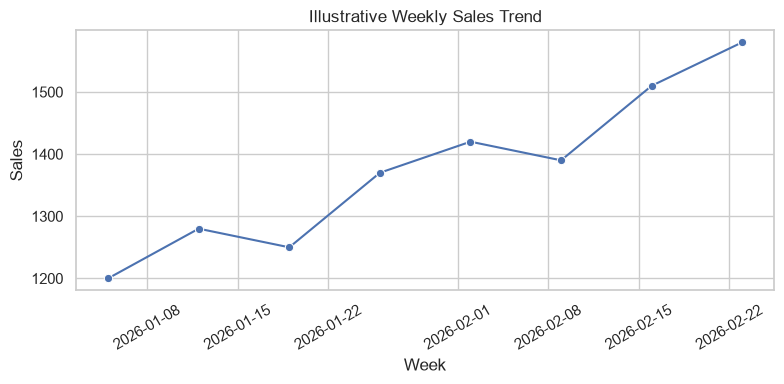

In [4]:
# Illustrative weekly sales series
weekly = pd.DataFrame({
    "week": pd.date_range("2026-01-05", periods=8, freq="W-MON"),
    "sales": [1200, 1280, 1250, 1370, 1420, 1390, 1510, 1580]
})
plt.figure(figsize=(8, 4))
sns.lineplot(data=weekly, x="week", y="sales", marker="o")
plt.title("Illustrative Weekly Sales Trend")
plt.xlabel("Week")
plt.ylabel("Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Observation:** The example series generally increases from the first to the last week, with a small dip along the way.

**Insight:** If these were actual business data, the team could investigate what drove growth and whether it is sustainable.

**Possible action:** Compare the trend with marketing campaigns, prices, stock availability, and seasonal effects before attributing a cause.

## 4. Relationships

A **relationship** describes how two variables vary together. A relationship may be positive, negative, weak, or nonlinear.

**Simple example:** More practice time may be associated with higher test scores.

**Real-world example:** Vehicle age may be associated with lower resale prices.

**Business example:** Discounts and profit may move in opposite directions.

**AI/ML use case:** Relationships help identify candidate features and multicollinearity risks.

**Why it matters:** Relationships can guide investigation and modeling, but correlation does not prove causation.

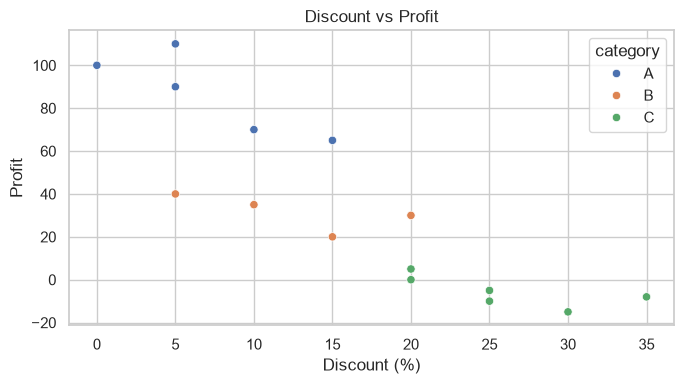

Correlation between discount and profit: -0.87


In [5]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=orders, x="discount_pct", y="profit", hue="category")
plt.title("Discount vs Profit")
plt.xlabel("Discount (%)")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

print("Correlation between discount and profit:", round(orders["discount_pct"].corr(orders["profit"]), 2))

**Observation:** Inspect whether higher discounts tend to appear with lower profit in this illustrative dataset.

**Insight:** If the pattern is present in real data, discount policies may need review—especially for low-margin products.

**Possible action:** Calculate profit margin by discount band and run a controlled test before changing discount policy.

## 5. Anomalies

An **anomaly** is an observation that differs noticeably from the rest. It may be a data-entry error, a rare event, or a legitimate exceptional case.

**Simple example:** One recorded exam score is 999 when scores should be between 0 and 100.

**Real-world example:** A sensor suddenly reports an impossible temperature.

**Business example:** A transaction is unusually large or has negative profit.

**AI/ML use case:** Anomaly detection can flag possible fraud, equipment issues, or data-quality problems.

**Why it matters:** Anomalies can distort summary statistics and models. Verify them rather than deleting them automatically.

Rows with negative profit:


,order_id,category,segment,sales,profit,discount_pct,delivery_days
9,10,C,Consumer,120,-10,25,6
11,12,C,Business,110,-15,30,7
12,13,C,Home Office,130,-5,25,6
14,15,C,Business,125,-8,35,8


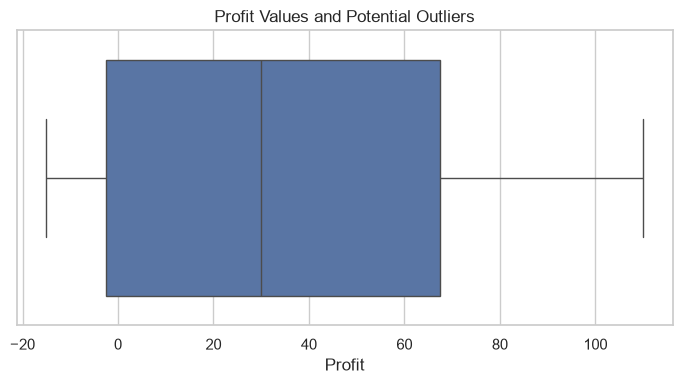

In [6]:
print("Rows with negative profit:")
display(orders[orders["profit"] < 0])

plt.figure(figsize=(7, 4))
sns.boxplot(data=orders, x="profit")
plt.title("Profit Values and Potential Outliers")
plt.xlabel("Profit")
plt.tight_layout()
plt.show()

**Observation:** Several example rows have negative profit.

**Insight:** These orders may be loss-making; the cause could involve discounting, costs, returns, or pricing. The dataset alone does not tell us which explanation is correct.

**Possible action:** Verify cost calculations and compare product, segment, and discount policies for loss-making orders.

## 6. Potential business problems

A **business problem** is a measurable gap between current performance and a desired outcome.

**Simple example:** Students are missing a target pass rate.

**Real-world example:** A delivery service has too many late shipments.

**Business example:** A category has high sales but repeated losses.

**AI/ML use case:** Predict late deliveries or likely customer churn to prioritize intervention.

**Why it matters:** A useful analysis links evidence to a clearly defined business metric and a decision owner.

In [7]:
problem_summary = orders.groupby("category", as_index=False).agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    negative_profit_orders=("profit", lambda values: (values < 0).sum()),
    average_delivery_days=("delivery_days", "mean")
)
problem_summary

,category,total_sales,total_profit,negative_profit_orders,average_delivery_days
0,A,2500,435,0,2.600000
1,B,1210,125,0,3.750000
2,C,775,-33,4,6.166667


**How to write the finding:** Avoid claiming a problem based on a single chart. State the metric, the comparison, the time period, and any uncertainty.

Example template: “During [period], [segment] had [measured result] compared with [comparison group]. This may indicate [possible explanation]. We recommend checking [additional evidence] before [action].”

## 7. Interesting segments

A **segment** is a meaningful subgroup, such as customer type, region, product category, or subscription tier.

**Simple example:** Compare reading progress for beginner and advanced learners.

**Real-world example:** Compare travel delays by route.

**Business example:** Compare average order value and profit across customer segments.

**AI/ML use case:** Segment-level analysis can help design features, evaluate model performance by subgroup, and identify where an intervention may work best.

**Why it matters:** Overall averages can hide important differences among groups.

In [8]:
segment_summary = orders.groupby("segment", as_index=False).agg(
    order_count=("order_id", "count"),
    average_sales=("sales", "mean"),
    total_profit=("profit", "sum"),
    average_delivery_days=("delivery_days", "mean")
).round(2)
segment_summary

,segment,order_count,average_sales,total_profit,average_delivery_days
0,Business,4,251.25,77,5.75
1,Consumer,8,320.00,350,3.62
2,Home Office,3,306.67,100,4.33


**Observation:** Compare both order counts and outcomes across segments.

**Insight:** A segment with high average sales may still have low total profit or few orders. Always check group size and multiple relevant metrics.

**Possible action:** Tailor further analysis to the segment with the clearest evidence of opportunity or risk.

## 8. Potential opportunities

An **opportunity** is a plausible way to improve outcomes based on evidence, such as reducing avoidable losses or improving service reliability.

**Simple example:** Provide extra practice on a topic where many learners struggle.

**Real-world example:** Adjust staffing during predictable busy periods.

**Business example:** Improve availability for products with strong demand and healthy margins.

**AI/ML use case:** Demand forecasting or recommendation models can support inventory and customer decisions.

**Why it matters:** Opportunities help turn descriptive analysis into testable actions. Estimate cost, benefit, and risk before investing.

In [ ]:
opportunity_summary = orders.groupby("category", as_index=False).agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    avg_discount=("discount_pct", "mean"),
    avg_delivery_days=("delivery_days", "mean")
)
opportunity_summary["profit_margin_pct"] = (
    opportunity_summary["total_profit"] / opportunity_summary["total_sales"] * 100
).round(1)
opportunity_summary

**Example interpretation:** A category with high sales but weak profit margin may be a candidate for cost, pricing, or discount analysis. A category with lower sales but positive margin may be an opportunity for carefully tested marketing.

**Possible action:** Rank opportunities by expected impact, confidence in evidence, cost, and ease of implementation.

## 9. Convert visualization → observation → insight → action

Use this structure for every important finding:

1. **Question:** What decision are we trying to support?
2. **Evidence:** Which table, metric, or graph supports the finding?
3. **Observation:** What exactly do the data show?
4. **Insight:** Why might the pattern matter?
5. **Validation:** What other data or checks are needed?
6. **Action:** What should be tested, changed, or monitored?
7. **Success metric:** How will we know whether the action helped?

### Weak vs strong writing

Weak: “The graph shows sales by category.”

Stronger: “Category A contributes the largest share of sales in this sample, while Category C contributes less. Before increasing promotion for A, compare profit margins and inventory availability to ensure additional sales would be profitable.”

The stronger statement names the pattern, explains why it matters, and identifies a sensible next check.